In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error 
from sklearn.model_selection import (KFold, cross_validate, cross_val_predict, train_test_split)
from scipy.stats import spearmanr
import shap
import time

TARGET = "peak_cell_floodable_area_m2" # "10cm_area"
GROUP_COL = None          # e.g. "catchment_id" / "cell_id" -- STRONGLY recommended if spatial/temporal autocorrelation
SEED = 42

from PrepDataFunctions import *
from ModelEvaluationFunctions import *

import sys, importlib
importlib.reload(sys.modules['ModelEvaluationFunctions'])
from ModelEvaluationFunctions import *

### Prepare data

In [17]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['rainpeak_sm_day_before_onset'].notna()]
print(len(df))

# Create a proportion floodable area flooded metric
df['peak_cell_floodable_area_km2'] = df['peak_cell_floodable_area_m2']*  0.000001
df['prop_floodable_area_flooded'] = (df['rainpeak_10cm_area']/df['peak_cell_floodable_area_km2'])*100

# Get early portion of data
subset_early = create_temporal_subset(df, "before", 2020).copy()

105580


In [7]:
# fig, ax = plt.subplots(figsize=(7, 7))
# sc = ax.scatter(subset_early['rainpeak_x_coord'], subset_early['rainpeak_y_coord'], c=subset_early['peak_cell_slope_max'],
#                  cmap='Reds', 
#                 vmin=0, 
#                  vmax=subset_early['peak_cell_slope_max'].abs().quantile(0.8), 
#                 s=12, alpha=0.6)
# plt.colorbar(sc, label='Peak cell slope maximum')
# ax.set_aspect('equal')
# ax.axis("off");

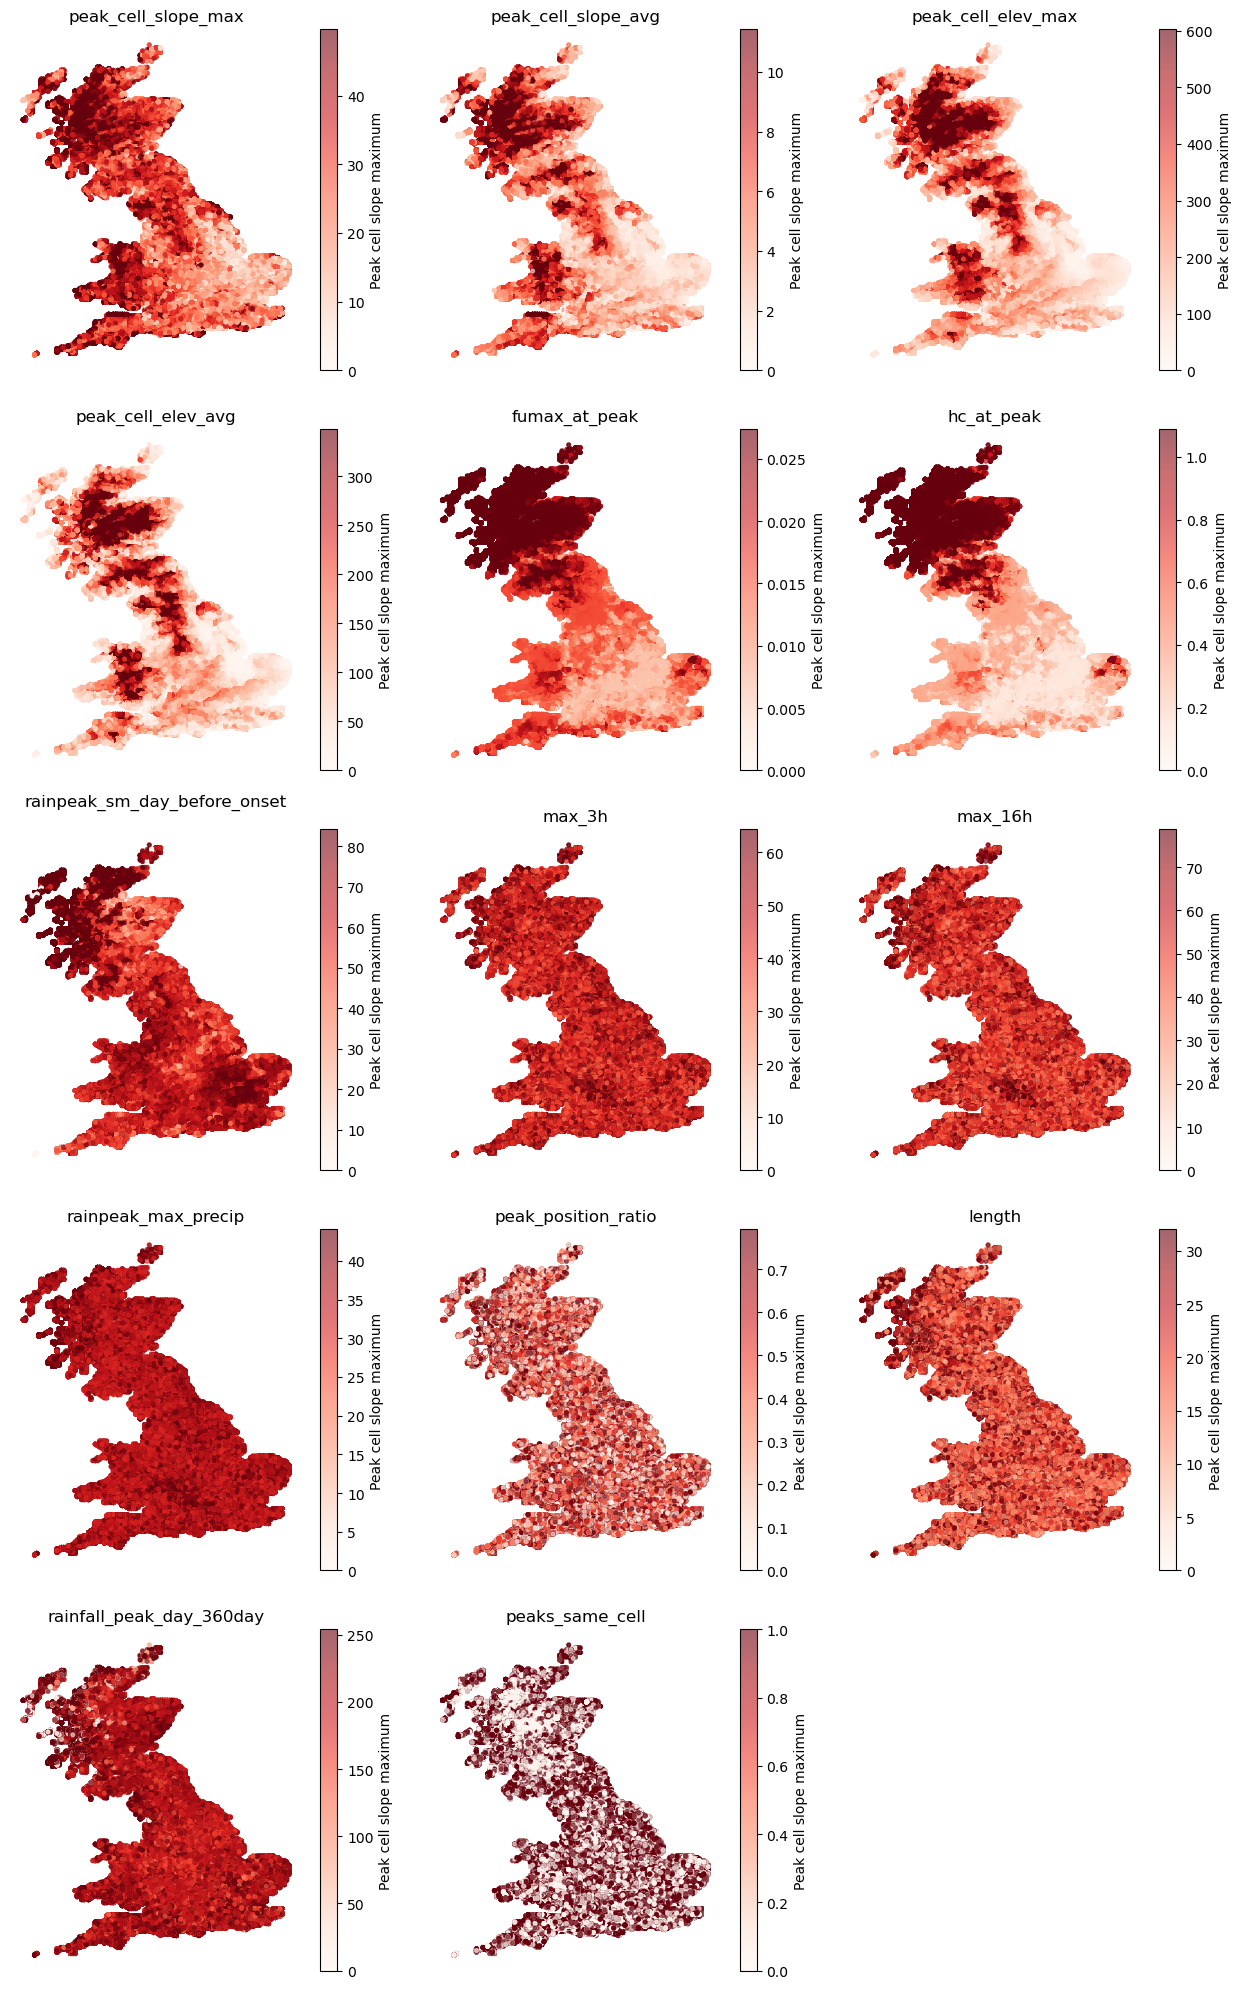

In [12]:
def plot_spatial_maps(df, cols=None, ncols=3, pct=98, s=3, cmap="RdBu_r",
                   shared_scale=False, figsize_per_panel=(4.2, 4)):
    cols = list(cols) if cols is not None else list(grouped.columns)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
                             squeeze=False)

    for ax, col in zip(axes.ravel(), cols):
        v = df[col].to_numpy()
        #lim = lim_shared if shared_scale else np.nanpercentile(np.abs(v), pct)
        sc = ax.scatter(df['rainpeak_x_coord'], df['rainpeak_y_coord'], c=df[col],cmap='Reds', vmin=0, 
                        vmax=df[col].abs().quantile(0.8),  s=7, alpha=0.6)        
        ax.axis("off");
        ax.set_title(col)
        plt.colorbar(sc, label='Peak cell slope maximum')
        
    for ax in axes.ravel()[len(cols):]:      # hide unused panels
        ax.axis("off")        
        
    plt.tight_layout()
    plt.show()
    
plot_spatial_maps(df, cols =['peak_cell_slope_max', 'peak_cell_slope_avg',
                            'peak_cell_elev_max', 'peak_cell_elev_avg',
                            "fumax_at_peak", "hc_at_peak", "rainpeak_sm_day_before_onset",
                             "max_3h", "max_16h", "rainpeak_max_precip",
                             "peak_position_ratio",
                            "length", "rainfall_peak_day_360day", "peaks_same_cell"
                            ] )    



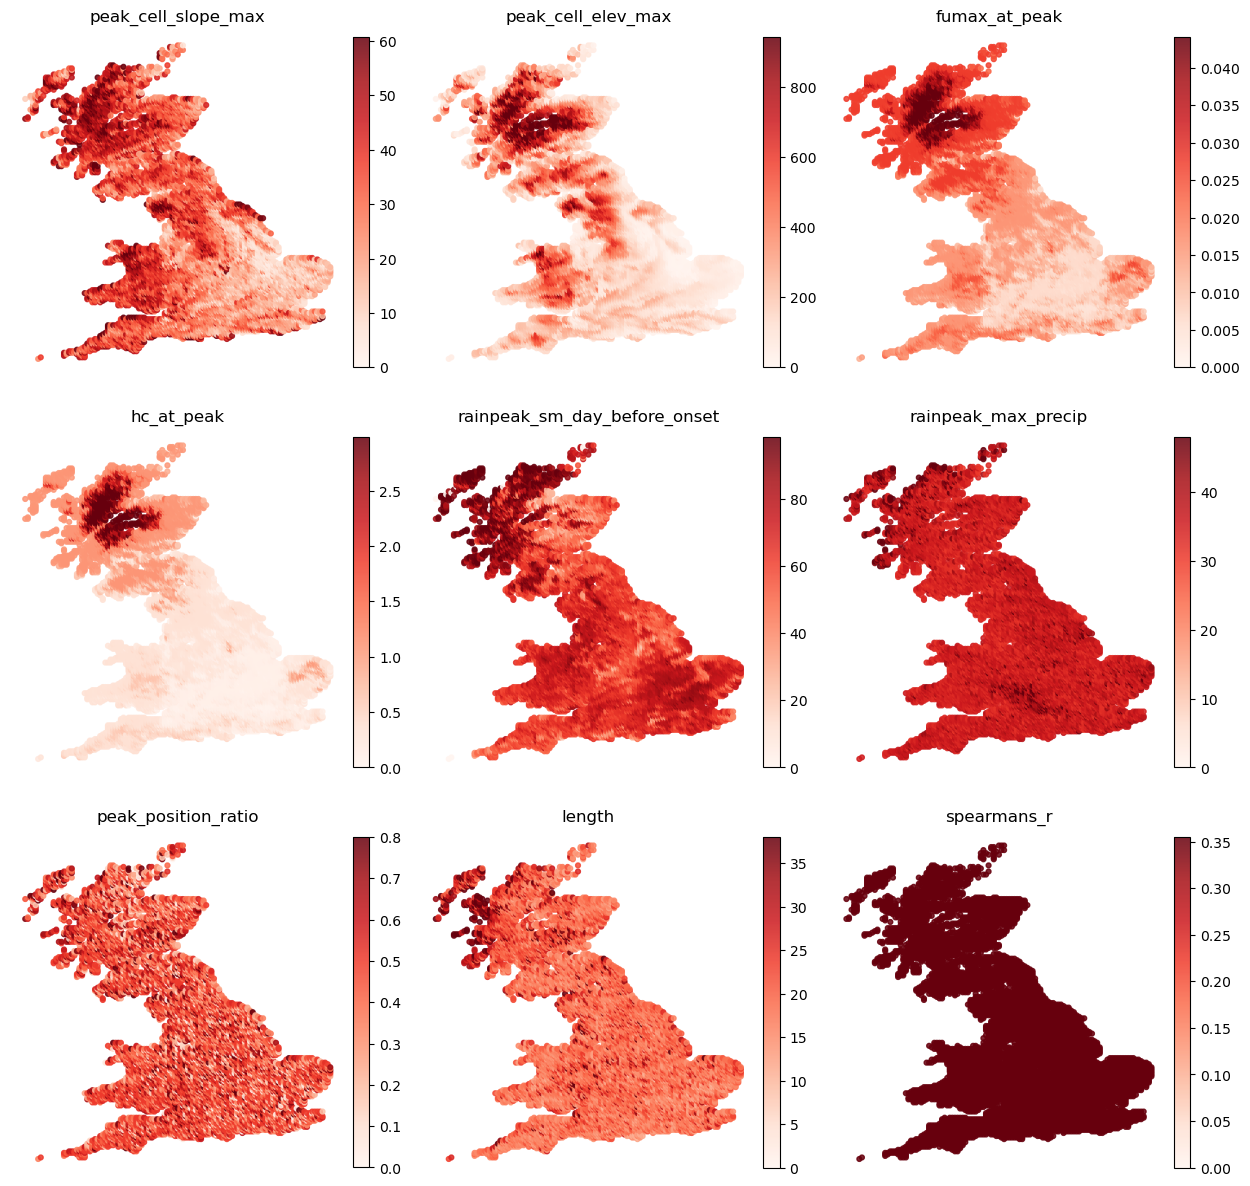

In [23]:
def plot_spatial_summary(df, cols, min_events=3, ncols=3,
                         figsize_per_panel=(4.2, 4), pct=98):

    # Aggregate events at each spatial location
    grouped = df.groupby(
        ['rainpeak_x_coord', 'rainpeak_y_coord']
    )

    counts = grouped.size().rename('n_events')
    medians = grouped[cols].median()

    spatial = medians.join(counts).reset_index()

    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_panel[0] * ncols,
                 figsize_per_panel[1] * nrows),
        squeeze=False
    )

    for ax, col in zip(axes.ravel(), cols):

        # Only plot locations with sufficient events
        sub = spatial[spatial['n_events'] >= min_events]

        vmax = sub[col].quantile(pct / 100)

        sc = ax.scatter(
            sub['rainpeak_x_coord'],
            sub['rainpeak_y_coord'],
            c=sub[col],
            cmap='Reds',
            vmin=0,
            vmax=vmax,
            s=12,
            alpha=0.85
        )

        ax.set_title(col)
        ax.axis('off')

        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.02)

    for ax in axes.ravel()[len(cols):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()
    
plot_spatial_summary(
    df,
    cols=[
        'peak_cell_slope_max',
        'peak_cell_elev_max',
        'fumax_at_peak',
        'hc_at_peak',
        'rainpeak_sm_day_before_onset',
        'rainpeak_max_precip',
        'peak_position_ratio',
        'length',"spearmans_r"
    ],
    min_events=3
)    

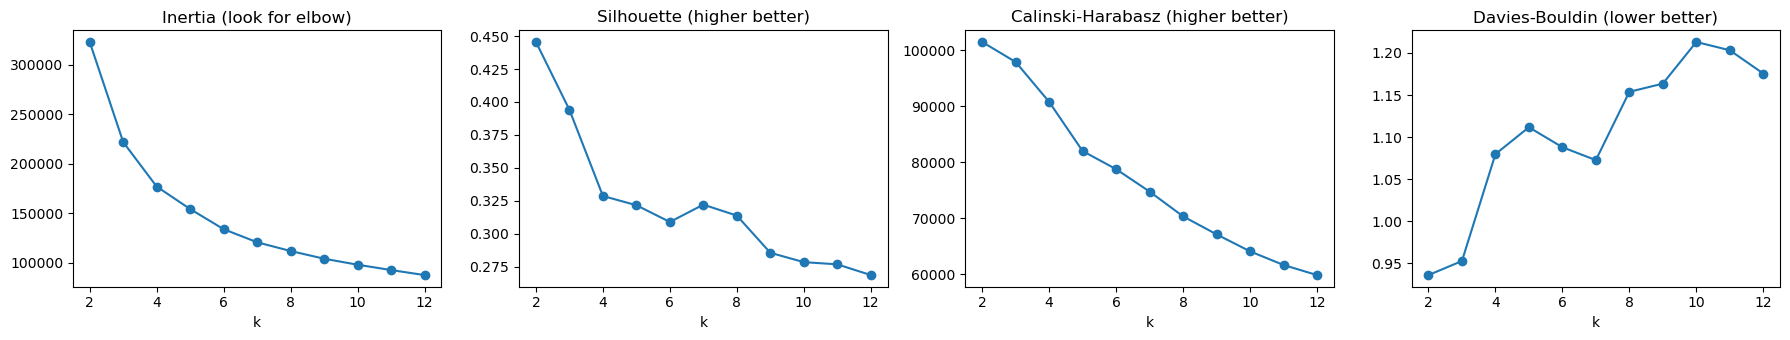

In [78]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import matplotlib.pyplot as plt

ks = range(2, 13)
res = {'k': [], 'inertia': [], 'silhouette': [], 'calinski': [], 'davies_bouldin': []}

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    res['k'].append(k)
    res['inertia'].append(km.inertia_)
    # silhouette is O(n^2), so subsample if you have many rows
    res['silhouette'].append(silhouette_score(X, km.labels_, sample_size=10000, random_state=0))
    res['calinski'].append(calinski_harabasz_score(X, km.labels_))
    res['davies_bouldin'].append(davies_bouldin_score(X, km.labels_))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (name, title) in zip(axes, [('inertia', 'Inertia (look for elbow)'),
                                    ('silhouette', 'Silhouette (higher better)'),
                                    ('calinski', 'Calinski-Harabasz (higher better)'),
                                    ('davies_bouldin', 'Davies-Bouldin (lower better)')]):
    ax.plot(res['k'], res[name], 'o-')
    ax.set_title(title); ax.set_xlabel('k')
plt.tight_layout(); plt.show()

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

feature_cols = ['peak_cell_slope_max', 'peak_cell_slope_avg',
                            'peak_cell_elev_max', 'peak_cell_elev_avg',
                            "fumax_at_peak", 
                            # "rainpeak_y_coord", "rainpeak_x_coord",
#                             "max_3h", "rainpeak_max_precip",
                            "hc_at_peak"] 

# Remove rows with NA values
valid_mask_1km = df[feature_cols].notna().all(axis=1)
df = df.loc[valid_mask_1km].reset_index(drop=True)

# Get the feature columns and appply a scaler
features = df[feature_cols]
scaler = StandardScaler()
X = scaler.fit_transform(features)

# Apply kmeans clustering
k = 7
kmeans = KMeans(n_clusters=k, random_state=0)
labels = kmeans.fit_predict(X)

# Apply cluster labels back to dataframe
df["cluster"] = labels
df["zone_id"] = np.arange(len(df))

In [81]:
# from sklearn.metrics import silhouette_score
# silhouette_score(X, kmeans.fit_predict(X))

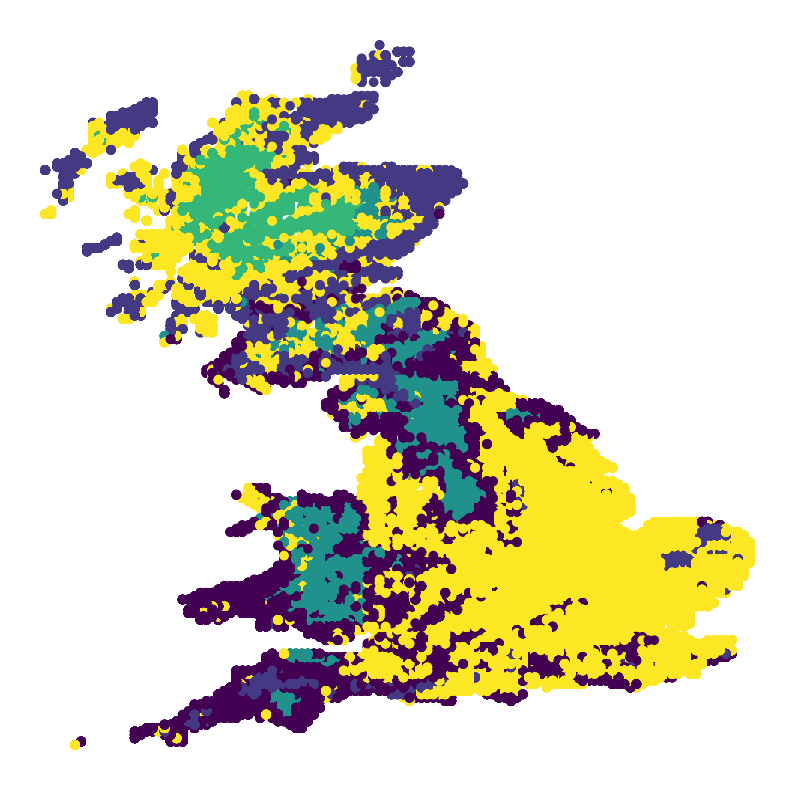

In [30]:
import matplotlib.colors as mcolors

fig, ax = plt.subplots(figsize=(10,10))

# Define discrete colormap (5 clusters → 5 colours)
cmap = plt.get_cmap("viridis", 7)

# Define boundaries so each integer gets its own colour bin
bounds = np.arange(-0.5, 5.5, 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Plot
sc = ax.scatter(df['rainpeak_x_coord'], df['rainpeak_y_coord'], c=df['cluster'],
                 cmap=cmap, norm = norm)        
ax.axis('off');

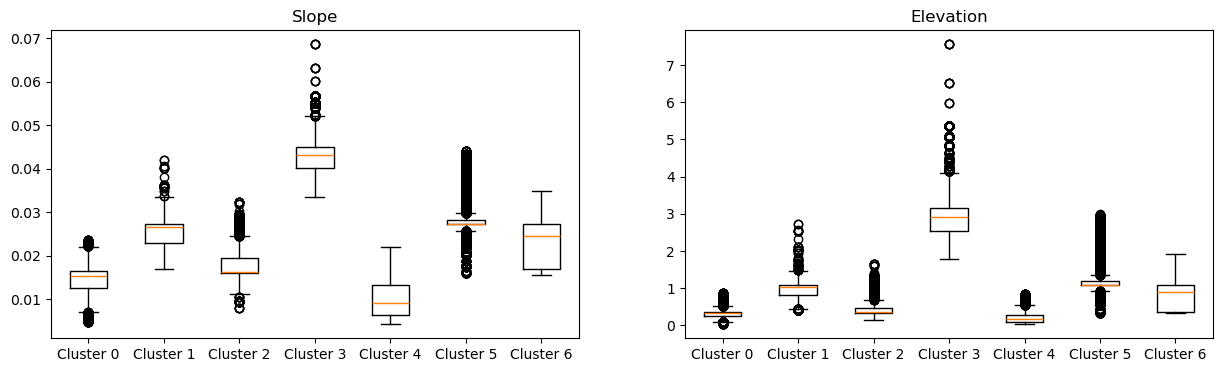

In [33]:
fig, axs = plt.subplots(ncols =2, figsize=(15, 4))
data_by_cluster = [df.loc[df["cluster"] == c, "fumax_at_peak"].dropna()
                    for c in range(k)]
axs[0].boxplot(data_by_cluster, tick_labels=[f"Cluster {c}" for c in range(k)])
axs[0].set_title("Slope")

data_by_cluster = [df.loc[df["cluster"] == c, "hc_at_peak"].dropna()
                    for c in range(k)]
axs[1].boxplot(data_by_cluster, tick_labels=[f"Cluster {c}" for c in range(k)])
axs[1].set_title("Elevation");

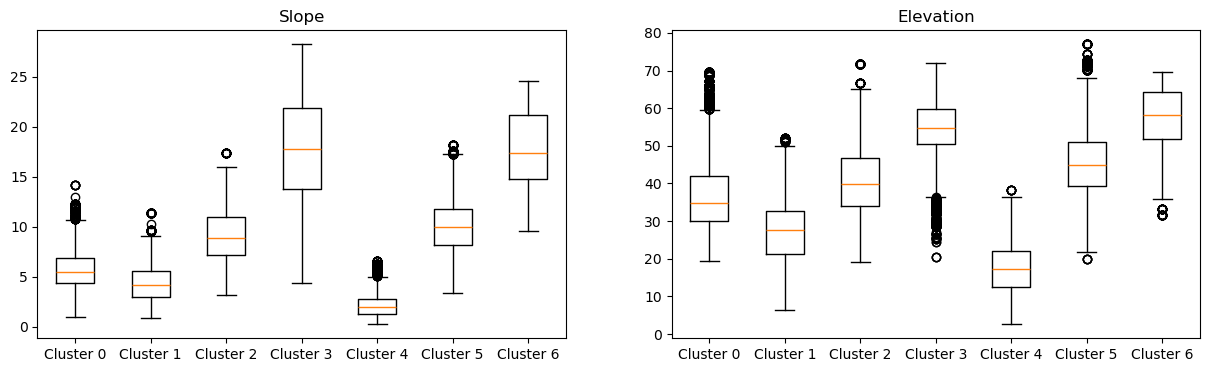

In [32]:
fig, axs = plt.subplots(ncols =2, figsize=(15, 4))
data_by_cluster = [df.loc[df["cluster"] == c, "peak_cell_slope_avg"].dropna()
                    for c in range(k)]
axs[0].boxplot(data_by_cluster, tick_labels=[f"Cluster {c}" for c in range(k)])
axs[0].set_title("Slope")

data_by_cluster = [df.loc[df["cluster"] == c, "peak_cell_slope_max"].dropna()
                    for c in range(k)]
axs[1].boxplot(data_by_cluster, tick_labels=[f"Cluster {c}" for c in range(k)])
axs[1].set_title("Elevation");

In [85]:
df.to_pickle(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_andclusters.pkl")